# 04 Revenue forecast

**Question:** What revenue can we expect in the next 3 months?

**Plan**
1. Input: monthly revenue from Q2, **full months only**.
2. Baseline: 3-month moving average (must match Q4).
3. Models: linear regression (trend + month-of-year pattern) and Holt's exponential smoothing (damped trend).
4. Time-based split: the last 3 months are the test. Metrics: MAE and MAPE. A rolling backtest adds more checks.
5. Forecast the next 3 months with a simple range, plot, and write the limits.

Revenue = item price without freight, valid sales only. All numbers are printed by code.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.linear_model import LinearRegression
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import plots  # noqa: E402

plots.setup()
OUT = ROOT / "sql" / "outputs"
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # Holt may report small optimiser notes; results are checked below
H = 3        # forecast horizon in months


def q(prefix):
    return pd.read_csv(next(OUT.glob(f"{prefix}_*.csv")))


def say(text):
    display(Markdown(text))


def money(x):
    return f"{x:,.0f}"

## 1. Input data: full months only

The data has very few orders in 2016 (one month is missing) and almost none after 2018-08 (see notebook 01, decision 11).
Those months would look like a crash and would break any trend, so they are removed. The flag `in_analysis_period` from Q2 does this.

In [2]:
q2 = q("q02")
removed = q2[~q2.in_analysis_period]
m = q2[q2.in_analysis_period][["year_month", "orders", "revenue"]].reset_index(drop=True)
m["period"] = pd.PeriodIndex(m.year_month, freq="M")
y = m.revenue.to_numpy(dtype=float)

say(f"Removed months: {', '.join(removed.year_month)} (together {int(removed.orders.sum())} orders, "
    f"{money(removed.revenue.sum())} revenue). Kept: **{len(m)} months**, {m.year_month.iloc[0]} to {m.year_month.iloc[-1]}.")

Removed months: 2016-09, 2016-10, 2016-12, 2018-09 (together 294 orders, 44,871 revenue). Kept: **20 months**, 2017-01 to 2018-08.

## 2. Baseline: 3-month moving average (must match Q4)

In [3]:
q4 = q("q04").set_index("year_month")
ma3 = pd.Series(y, index=m.year_month).rolling(3).mean()
diff = (ma3 - q4.moving_avg_3m).abs().max()
assert diff < 0.011, diff
print(f"Moving average in pandas vs SQL Q4: largest difference = {diff:.4f} (rounding only). They match.")

Moving average in pandas vs SQL Q4: largest difference = 0.0033 (rounding only). They match.


**How the baseline forecasts:** it predicts every future month as the average of the **last 3 known months**. It has no trend.
It is the number to beat: a model must be better than this simple rule to be worth using.

## 3. The models

In [4]:
def baseline(y_train, h, first_period):
    return np.repeat(y_train[-3:].mean(), h)


def linear_trend_month(y_train, h, first_period):
    '''Linear regression on: time (trend) plus sin and cos of the month of the year (a smooth yearly pattern).
    With under two years of data, one separate flag per month cannot be learned, so a smooth pattern is used.'''
    n = len(y_train)
    periods = pd.period_range(first_period, periods=n + h, freq="M")
    month = periods.month.to_numpy()
    X = np.column_stack([np.arange(n + h), np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12)])
    model = LinearRegression().fit(X[:n], y_train)
    return model.predict(X[n:])


def holt_damped(y_train, h, first_period):
    '''Holt exponential smoothing with a damped trend. Seasonal Holt-Winters needs at least 2 full years of data;
    we have less, so no seasonal part.'''
    fit = ExponentialSmoothing(y_train, trend="add", damped_trend=True, seasonal=None,
                               initialization_method="estimated").fit()
    return fit.forecast(h)


MODELS = {"Moving average (baseline)": baseline, "Linear regression": linear_trend_month, "Holt (damped trend)": holt_damped}


def mae(actual, pred):
    return float(np.mean(np.abs(actual - pred)))


def mape(actual, pred):
    return float(np.mean(np.abs(actual - pred) / actual) * 100)

## 4. Test: time-based split (last 3 months are the test)

The model sees only the first months and must predict the last 3. Data is never shuffled: the future must not leak into the past.

In [5]:
n_train = len(y) - H
y_train, y_test = y[:n_train], y[n_train:]
first = m.period.iloc[0]

test_pred = {name: fn(y_train, H, first) for name, fn in MODELS.items()}
split_metrics = pd.DataFrame({
    name: {"MAE": mae(y_test, p), "MAPE %": mape(y_test, p)} for name, p in test_pred.items()
}).T.round(2)
say(f"Train: {m.year_month.iloc[0]} to {m.year_month.iloc[n_train - 1]} ({n_train} months). "
    f"Test: {', '.join(m.year_month.iloc[n_train:])}.")

# The baseline forecast is the Q4 moving average of the last training month
assert abs(test_pred["Moving average (baseline)"][0] - q4.loc[m.year_month.iloc[n_train - 1], "moving_avg_3m"]) < 0.011
display(split_metrics)
display(pd.DataFrame({"actual": y_test, **{k: v for k, v in test_pred.items()}}, index=m.year_month.iloc[n_train:]).round(0))

Train: 2017-01 to 2018-05 (17 months). Test: 2018-06, 2018-07, 2018-08.

,MAE,MAPE %
Moving average (baseline),125781.96,14.59
Linear regression,302850.13,35.15
Holt (damped trend),267284.85,31.01


,actual,Moving average (baseline),Linear regression,Holt (damped trend)
year_month,,,,
2018-06,863266.0,989172.0,1101860.0,1087494.0
2018-07,878044.0,989172.0,1164631.0,1130953.0
2018-08,848860.0,989172.0,1232229.0,1173577.0


## 5. Rolling backtest (more than one test)

Three test months is very little. So we repeat the test many times: train on the first *k* months, forecast the next 3,
move one month forward, and repeat. The average error over all folds is a more stable guide than a single split.

In [6]:
MIN_TRAIN = 10
rows = []
for k in range(MIN_TRAIN, len(y) - H + 1):
    for name, fn in MODELS.items():
        pred = fn(y[:k], H, first)
        rows.append({"model": name, "train_months": k, "MAE": mae(y[k:k + H], pred), "MAPE %": mape(y[k:k + H], pred)})
folds = pd.DataFrame(rows)
rolling = folds.groupby("model")[["MAE", "MAPE %"]].mean().loc[list(MODELS)].round(2)
n_folds = folds.train_months.nunique()
say(f"Rolling backtest: {n_folds} folds (training on {MIN_TRAIN} up to {len(y) - H} months, each time forecasting the next {H} months).")
display(rolling)

best_name = rolling["MAPE %"].idxmin()
better_than_baseline = rolling.loc[best_name, "MAPE %"] < rolling.loc["Moving average (baseline)", "MAPE %"]
say(f"**Best model by rolling-backtest MAPE: {best_name}** (MAPE {rolling.loc[best_name, 'MAPE %']:.2f}%). "
    f"Baseline MAPE: {rolling.loc['Moving average (baseline)', 'MAPE %']:.2f}%. "
    + ("The model beats the baseline." if best_name != "Moving average (baseline)" else
       "No model beats the simple baseline, so the baseline is the forecast we use."))

Rolling backtest: 8 folds (training on 10 up to 17 months, each time forecasting the next 3 months).

,MAE,MAPE %
model,,
Moving average (baseline),122037.54,13.13
Linear regression,203009.59,23.22
Holt (damped trend),129570.41,14.54


**Best model by rolling-backtest MAPE: Moving average (baseline)** (MAPE 13.13%). Baseline MAPE: 13.13%. No model beats the simple baseline, so the baseline is the forecast we use.

## 6. Forecast the next 3 months

In [7]:
best_fn = MODELS[best_name]
future_periods = pd.period_range(m.period.iloc[-1] + 1, periods=H, freq="M")
future = best_fn(y, H, first)
err = rolling.loc[best_name, "MAPE %"] / 100      # simple range: forecast +/- the typical backtest error (MAPE)
forecast = pd.DataFrame({"month": future_periods.strftime("%Y-%m"), "forecast": future,
                         "low": future * (1 - err), "high": future * (1 + err)}).round(0)
say(f"Simple range = forecast times (1 +/- {100 * err:.1f}%), where {100 * err:.1f}% is the average MAPE of {best_name} in the rolling backtest.")
display(forecast)
forecast.to_csv(ROOT / "reports" / "forecast_next_3_months.csv", index=False)

Simple range = forecast times (1 +/- 13.1%), where 13.1% is the average MAPE of Moving average (baseline) in the rolling backtest.

,month,forecast,low,high
0,2018-09,863390.0,750027.0,976753.0
1,2018-10,863390.0,750027.0,976753.0
2,2018-11,863390.0,750027.0,976753.0


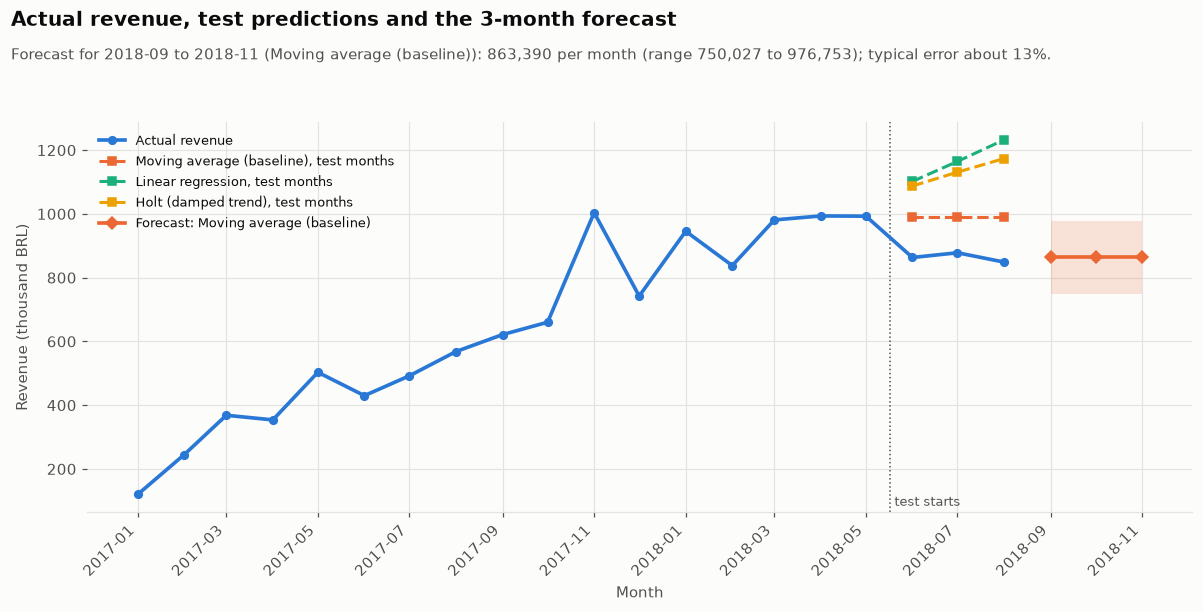

**Takeaway:** Forecast for 2018-09 to 2018-11 (Moving average (baseline)): 863,390 per month (range 750,027 to 976,753); typical error about 13%.

In [8]:
fig, ax = plt.subplots(figsize=(11, 5.6))
x = m.period.dt.to_timestamp()
COLORS = {"Moving average (baseline)": plots.ORANGE, "Linear regression": "#1baf7a", "Holt (damped trend)": "#eda100"}

ax.plot(x, y / 1000, color=plots.BLUE, linewidth=2.4, marker="o", markersize=5, label="Actual revenue", zorder=3)
x_test = x.iloc[n_train:]
for name, pred in test_pred.items():
    ax.plot(x_test, pred / 1000, color=COLORS[name], linewidth=2, linestyle="--", marker="s", markersize=5, label=f"{name}, test months")

x_future = future_periods.to_timestamp()
ax.fill_between(x_future, forecast.low / 1000, forecast.high / 1000, color=COLORS[best_name], alpha=0.18, linewidth=0)
ax.plot(x_future, future / 1000, color=COLORS[best_name], linewidth=2.4, marker="D", markersize=6, label=f"Forecast: {best_name}")
ax.axvline(x.iloc[n_train] - pd.Timedelta(days=15), color=plots.INK_2, linewidth=1, linestyle=":")
ax.text(x.iloc[n_train] - pd.Timedelta(days=12), ax.get_ylim()[0] + 10, "test starts", fontsize=8.5, color=plots.INK_2, va="bottom")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (thousand BRL)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend(loc="upper left", fontsize=8.5)

first_f, last_f = forecast.iloc[0], forecast.iloc[-1]
level = money(first_f.forecast) if first_f.forecast == last_f.forecast else f"{money(first_f.forecast)} to {money(last_f.forecast)}"
takeaway = (f"Forecast for {first_f.month} to {last_f.month} ({best_name}): {level} per month "
            f"(range {money(first_f.low)} to {money(last_f.high)}); typical error about {100 * err:.0f}%.")
plots.finish(fig, "Actual revenue, test predictions and the 3-month forecast", takeaway, "forecast_01_actual_vs_predicted.png")
say("**Takeaway:** " + takeaway)

## 7. Limits (read before using the numbers)

In [9]:
nov = m[m.year_month.str.endswith("-11")]
say(f'''
- **Very little history.** Only {len(m)} full months, and each calendar month appears once or twice. Seasonal patterns cannot be learned
  reliably, and Holt-Winters with a seasonal part was not possible (it needs at least 24 months).
- **No holiday information.** The highest month was {m.loc[m.revenue.idxmax(), 'year_month']} ({money(m.revenue.max())}), probably a sale event.
  The data has only one November, and none of the models knows about it. A forecast that includes November 2018 may be too low if
  there is a sale again.
- **Growth changed.** Revenue grew fast in 2017 and was flat in 2018 (see notebook 02). A trend learned from fast growth can look too hopeful.
- **Only 3 test months, plus {n_folds} backtest folds that overlap.** The error numbers are rough. Do not read small differences between
  models as real.
- **No outside factors.** Marketing, prices, new sellers, delivery problems and the economy are not in the model.
- **The data ends in 2018.** The forecast covers the 3 months after the end of the data, so it cannot be compared with real results.
  Treat it as a method demo.
''')


- **Very little history.** Only 20 full months, and each calendar month appears once or twice. Seasonal patterns cannot be learned
  reliably, and Holt-Winters with a seasonal part was not possible (it needs at least 24 months).
- **No holiday information.** The highest month was 2017-11 (1,003,862), probably a sale event.
  The data has only one November, and none of the models knows about it. A forecast that includes November 2018 may be too low if
  there is a sale again.
- **Growth changed.** Revenue grew fast in 2017 and was flat in 2018 (see notebook 02). A trend learned from fast growth can look too hopeful.
- **Only 3 test months, plus 8 backtest folds that overlap.** The error numbers are rough. Do not read small differences between
  models as real.
- **No outside factors.** Marketing, prices, new sellers, delivery problems and the economy are not in the model.
- **The data ends in 2018.** The forecast covers the 3 months after the end of the data, so it cannot be compared with real results.
  Treat it as a method demo.


## Save the key results for the report

In [10]:
import json

results = {
    "source": "notebooks/04_forecast.ipynb",
    "months_used": int(len(m)), "first_month": str(m.year_month.iloc[0]), "last_month": str(m.year_month.iloc[-1]),
    "removed_months": list(removed.year_month),
    "best_model_by_rolling_mape": str(best_name),
    "rolling_backtest": {k: {"mae": float(v["MAE"]), "mape_pct": float(v["MAPE %"])} for k, v in rolling.iterrows()},
    "test_split": {k: {"mae": float(v["MAE"]), "mape_pct": float(v["MAPE %"])} for k, v in split_metrics.iterrows()},
    "forecast_months": list(forecast.month), "forecast_per_month": [float(x) for x in forecast.forecast],
    "forecast_low": [float(x) for x in forecast.low], "forecast_high": [float(x) for x in forecast.high],
    "range_pct": float(100 * err),
}
(ROOT / "reports" / "forecast_results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print("saved reports/forecast_results.json")

saved reports/forecast_results.json
